In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

file_path = Path("data/sample.nc")

ds = xr.open_dataset(file_path)
ds

<xarray.Dataset> Size: 180kB
Dimensions:                 (scanline: 100, pixel: 200)
Dimensions without coordinates: scanline, pixel
Data variables:
    brightness_temperature  (scanline, pixel) float64 160kB ...
    quality_flag            (scanline, pixel) int8 20kB ...
Attributes:
    platform:            Synthetic satellite
    product_level:       L1
    processing_version:  1.0

In [5]:
# Dataset dimensions
print("Dimensions:", dict(ds.sizes))

# Variables
print("\nVariables:", list(ds.data_vars))

# Global metadata
print("\nGlobal attributes:")
for key, value in ds.attrs.items():
    print(f"{key}: {value}")

Dimensions: {'scanline': 100, 'pixel': 200}

Variables: ['brightness_temperature', 'quality_flag']

Global attributes:
platform: Synthetic satellite
product_level: L1
processing_version: 1.0


In [6]:
# Brightness temperature
temperature = ds["brightness_temperature"]

print("Temperature shape:", temperature.shape)
print("Temperature units:", temperature.attrs["units"])
print("Temperature description:", temperature.attrs["long_name"])

display(temperature.to_dataframe().head(20))

Temperature shape: (100, 200)
Temperature units: K
Temperature description: Brightness temperature


brightness_temperature
scanline pixel                        
0        0                         NaN
         1                  274.800079
         2                  283.752256
         3                  284.702824
         4                  270.244824
         5                  273.489102
         6                  280.639202
         7                  278.418787
         8                  279.915994
         9                  275.734780
         10                 284.396990
         11                 283.888960
         12                 280.330153
         13                 285.636206
         14                 282.337547
         15                 275.703538
         16                 281.843754
         17                 275.205587
         18                 284.392252
         19                 279.750370

In [4]:
quality_flag = ds["quality_flag"]

print("Quality flag meanings:", quality_flag.attrs["flag_meanings"])
print("Unique quality flags:", np.unique(quality_flag.values))

Quality flag meanings: good suspect invalid
Unique quality flags: [0 1 2]


In [5]:
total_records = temperature.size
missing_records = int(temperature.isnull().sum().item())

missing_rate = 100 * missing_records / total_records

print(f"Total records: {total_records}")
print(f"Missing records: {missing_records}")
print(f"Missing rate: {missing_rate:.3f}%")

Total records: 20000
Missing records: 2
Missing rate: 0.010%


In [6]:
stats = {
    "Minimum (K)": float(temperature.min(skipna=True)),
    "Maximum (K)": float(temperature.max(skipna=True)),
    "Mean (K)": float(temperature.mean(skipna=True)),
    "Median (K)": float(temperature.median(skipna=True)),
    "Standard deviation (K)": float(temperature.std(skipna=True)),
}

pd.Series(stats, name="Value").to_frame()

,Value
Minimum (K),258.054427
Maximum (K),300.756207
Mean (K),280.024829
Median (K),279.990842
Standard deviation (K),5.023521


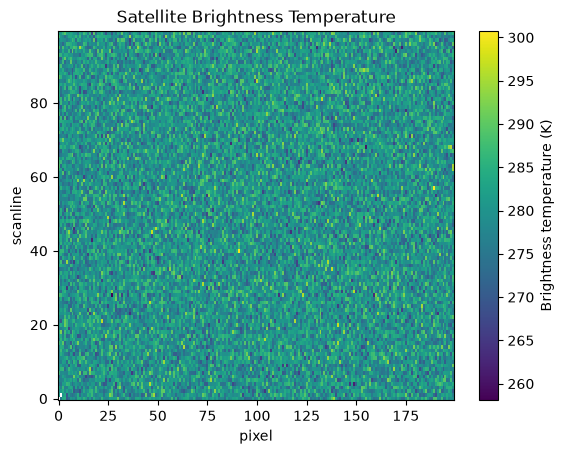

In [7]:
temperature.plot(
    x="pixel",
    y="scanline",
    cmap="viridis",
    cbar_kwargs={"label": "Brightness temperature (K)"},
)

plt.title("Satellite Brightness Temperature")
plt.show()

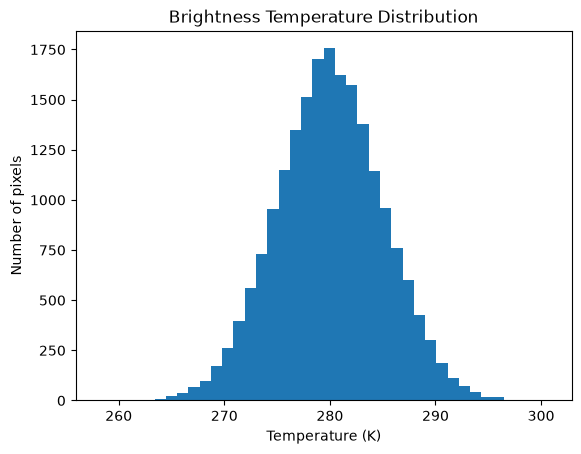

In [8]:
temperature.plot.hist(bins=40)

plt.title("Brightness Temperature Distribution")
plt.xlabel("Temperature (K)")
plt.ylabel("Number of pixels")
plt.show()

In [9]:
flag_counts = (
    quality_flag
    .to_series()
    .value_counts()
    .sort_index()
)

flag_summary = pd.DataFrame({
    "Count": flag_counts,
    "Percentage": 100 * flag_counts / quality_flag.size,
})

flag_summary.index.name = "Quality Flag"
display(flag_summary)

,Count,Percentage
Quality Flag,,
0,19000,95.00
1,604,3.02
2,396,1.98


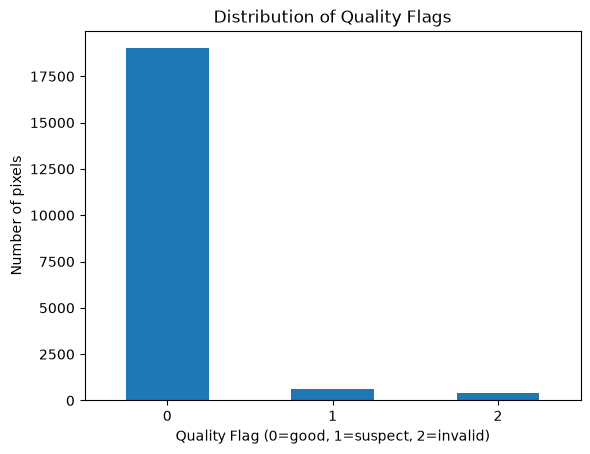

In [10]:
flag_counts.plot(kind="bar")

plt.title("Distribution of Quality Flags")
plt.xlabel("Quality Flag (0=good, 1=suspect, 2=invalid)")
plt.ylabel("Number of pixels")
plt.xticks(rotation=0)
plt.show()

In [12]:
good_mask = quality_flag == 0
good_temperature = temperature.where(good_mask)

print(
    "Valid good pixels:",
    int(good_temperature.count().item())
)

print(
    "Mean temperature of good pixels:",
    round(float(good_temperature.mean(skipna=True)), 2),
    "K",
)

Valid good pixels: 18998
Mean temperature of good pixels: 280.04 K


In [13]:
df = ds[
    ["brightness_temperature", "quality_flag"]
].to_dataframe().reset_index()

display(df.head(10))

,scanline,pixel,brightness_temperature,quality_flag
0,0,0,NaN,0
1,0,1,274.800079,0
2,0,2,283.752256,0
3,0,3,284.702824,0
4,0,4,270.244824,0
5,0,5,273.489102,0
6,0,6,280.639202,0
7,0,7,278.418787,0
8,0,8,279.915994,1
9,0,9,275.734780,0


In [14]:
df.to_csv("data/sample_analysis.csv", index=False)

In [15]:
ds.close()